In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

# Cargar los dos archivos
anp = pd.read_csv("/content/drive/MyDrive/Proyecto_MapBiomas/alerta_fusion_con_anp.csv")
ti  = pd.read_csv("/content/drive/MyDrive/Proyecto_MapBiomas/alertas_con_ti.csv")

# Del CSV de TI solo necesitas dos columnas
ti_slim = ti[['alert_d', 'ti_final']].drop_duplicates('alert_d')

# Merge: left join para no perder ninguna fila del ANP
df = anp.merge(ti_slim, on='alert_d', how='left')

# Las alertas fuera de TI que no matchearon quedan como NaN → llenarlas
df['ti_final'] = df['ti_final'].fillna('fuera_ti')

# Verificación
print("Filas finales:", len(df))
print("\nDistribución TI:")
print(df['ti_final'].value_counts())
print("\nDistribución destino:")
print(df['destino'].value_counts())
print("\nColumnas finales:")
print(df.columns.tolist())

# Guardar
df.to_csv("/content/drive/MyDrive/Proyecto_MapBiomas/data_limpia/tabla_maestra_final.csv", index=False)
print("\n✅ tabla_maestra_final.csv guardada")

Filas finales: 21870

Distribución TI:
ti_final
fuera_ti         16931
ti_titulada       4349
ti_en_proceso      590
Name: count, dtype: int64

Distribución destino:
destino
D1_agricultura       15861
D5_bosque             4472
D3_suelo_expuesto      881
D2b_mineria            611
D4_regeneracion         45
Name: count, dtype: int64

Columnas finales:
['alert_d', 'ani_lrt', 'area_ha', 'log_are', 'clase_T1', 'clase_T1_raw', 'clase_Tplus1', 'destino', 'gini', 'flag_mixta', 'flag_excluir', 'flag_sin_T1p', 'fch_lrt', 'tip_lrt', 'tip_mcr', 'dprtmnt', 'dist_via_km', 'log_dist_via', 'anp_categoria', 'carretera_cerca', 'dentro_ANP_dummy', 'interaccion_carretera_anp', 'ti_final']

✅ tabla_maestra_final.csv guardada


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELDA 1 — AUTENTICACIÓN E INICIALIZACIÓN GEE
# ══════════════════════════════════════════════════════════════════════════════
import ee
ee.Authenticate()
ee.Initialize(project='tesis-481703')
print('✅ GEE inicializado correctamente')

✅ GEE inicializado correctamente


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELDA 2 — DESCARGAR VÍAS OSM DE MADRE DE DIOS (sin GEE)
# ══════════════════════════════════════════════════════════════════════════════
import subprocess
import geopandas as gpd
from shapely.geometry import box

# Instalar dependencias
subprocess.run(["pip", "install", "-q", "pyogrio"])

# ── Descargar PBF de Perú desde Geofabrik ──────────────────────────────────
url = "https://download.geofabrik.de/south-america/peru-latest.osm.pbf"
subprocess.run(["wget", "-q", "--show-progress", "-O", "peru.osm.pbf", url])
print("✅ PBF descargado")

✅ PBF descargado


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELDA 3 — FILTRAR POR BBOX DE MADRE DE DIOS
# ══════════════════════════════════════════════════════════════════════════════
import fiona

# Bbox Madre de Dios
bbox_mdd = (-71.5, -13.5, -68.5, -10.5)  # (xmin, ymin, xmax, ymax)

# Leer solo líneas con highway dentro del bbox
vias_mdd = gpd.read_file(
    "peru.osm.pbf",
    layer="lines",
    bbox=bbox_mdd,
    engine="pyogrio"
)

# Filtrar solo filas con valor en 'highway'
vias_mdd = vias_mdd[vias_mdd["highway"].notna()].copy()

print(f"✅ Vías encontradas: {len(vias_mdd):,}")
print(vias_mdd["highway"].value_counts())

✅ Vías encontradas: 7,490
highway
residential       3162
path              1285
track              749
unclassified       744
service            557
trunk              277
footway            275
tertiary           264
secondary           91
primary             46
steps               13
trunk_link          10
secondary_link       7
living_street        4
pedestrian           4
corridor             1
tertiary_link        1
Name: count, dtype: int64


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELDA 4 — EXPORTAR A SHAPEFILE O GEOJSON
# ══════════════════════════════════════════════════════════════════════════════
vias_mdd.to_file("vias_mdd_todas.geojson", driver="GeoJSON")
# o shapefile:
# vias_mdd.to_file("vias_mdd_todas.shp")
print("✅ Archivo exportado")

✅ Archivo exportado


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELDA 1 — INSTALAR DEPENDENCIAS Y DESCARGAR PBF (solo una vez)
# ══════════════════════════════════════════════════════════════════════════════
import subprocess
subprocess.run(["pip", "install", "-q", "pyogrio", "geopandas"])

import geopandas as gpd
import pandas as pd
from shapely.geometry import box
from google.colab import drive

# Montar Drive para guardar resultados
drive.mount('/content/drive')

# Descargar PBF de Perú (~120 MB, solo una vez)
import os
if not os.path.exists("peru.osm.pbf"):
    subprocess.run(["wget", "-q", "--show-progress",
                    "-O", "peru.osm.pbf",
                    "https://download.geofabrik.de/south-america/peru-latest.osm.pbf"])
    print("✅ PBF descargado")
else:
    print("✅ PBF ya existe, se reutiliza")

Mounted at /content/drive
✅ PBF ya existe, se reutiliza


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELDA 2 — DEFINIR REGIONES Y TIPOS DE VÍA
# ══════════════════════════════════════════════════════════════════════════════

regiones = {
    "mdd":       (-71.5, -13.5, -68.5, -10.5),
    "ucayali":   (-76.5, -11.5, -70.5,  -6.0),
    "loreto":    (-77.5,  -7.5, -69.0,  -0.5),
    "sanmartin": (-78.5,  -8.5, -75.0,  -5.0),
    "amazonas":  (-79.5,  -7.5, -77.0,  -3.0),
    "huanuco":   (-77.5, -10.5, -74.5,  -8.0),
    "pasco":     (-76.5, -11.0, -74.5,  -9.0),
    "junin":     (-76.5, -12.5, -73.5,  -9.5),
    "cusco":     (-74.5, -14.5, -70.0, -11.0),
}

tipos_via = ["primary", "secondary", "tertiary", "unclassified", "track"]

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELDA 3 — EXTRAER VÍAS POR REGIÓN Y UNIR TODO
# ══════════════════════════════════════════════════════════════════════════════

gdfs = []

for nombre, bbox in regiones.items():
    print(f"⏳ Procesando {nombre}...")
    gdf = gpd.read_file(
        "peru.osm.pbf",
        layer="lines",
        bbox=bbox,
        engine="pyogrio"
    )
    # Filtrar por highway y tipos de vía
    gdf = gdf[gdf["highway"].isin(tipos_via)].copy()
    gdf["region"] = nombre
    gdfs.append(gdf)
    print(f"   ✅ {nombre}: {len(gdf):,} vías")

# Unir todo
vias_total = pd.concat(gdfs, ignore_index=True)
vias_total = gpd.GeoDataFrame(vias_total, crs="EPSG:4326")

print(f"\n📊 Total vías: {len(vias_total):,}")
print(vias_total["highway"].value_counts())

⏳ Procesando mdd...
   ✅ mdd: 1,894 vías
⏳ Procesando ucayali...
   ✅ ucayali: 18,607 vías
⏳ Procesando loreto...
   ✅ loreto: 7,318 vías
⏳ Procesando sanmartin...
   ✅ sanmartin: 15,946 vías
⏳ Procesando amazonas...
   ✅ amazonas: 16,241 vías
⏳ Procesando huanuco...
   ✅ huanuco: 11,539 vías
⏳ Procesando pasco...
   ✅ pasco: 7,263 vías
⏳ Procesando junin...
   ✅ junin: 23,224 vías
⏳ Procesando cusco...
   ✅ cusco: 40,602 vías

📊 Total vías: 142,634
highway
unclassified    65395
track           45367
tertiary        21628
primary          5350
secondary        4894
Name: count, dtype: int64


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELDA 4 — EXPORTAR A DRIVE (GPKG + SHP)
# ══════════════════════════════════════════════════════════════════════════════

ruta_salida = "/content/drive/MyDrive/Proyecto_MapBiomas/data_limpia/"
os.makedirs(ruta_salida, exist_ok=True)

# GeoPackage (recomendado)
vias_total.to_file(ruta_salida + "vias_osm_total.gpkg", driver="GPKG")
print("✅ GPKG guardado")

# Shapefile
vias_total.to_file(ruta_salida + "vias_osm_total.shp")
print("✅ SHP guardado")

✅ GPKG guardado
✅ SHP guardado


/usr/local/lib/python3.12/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Value '"description"=>"Los nacionales del Ecuador podrán transitar libremente por una única vía pública carrozable de hasta cinco metros de ancho que conecte el área transferida en propiedad con el territorio del Ecuador.","source:date"=>"1998","source_ref"=>"https://www4.congreso.gob.pe/comisiones/1999/exteriores/libro1/2avolum/01proto.htm"' of field other_tags has been truncated to 254 characters.  This warning will not be emitted any more for that layer.
  ogr_write(


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELDA 5 — EXPLORAR ATRIBUTOS Y TIPOS DE VÍA
# ══════════════════════════════════════════════════════════════════════════════

# ── 1. Columnas disponibles ────────────────────────────────────────────────
print("📋 COLUMNAS DISPONIBLES:")
print(vias_total.columns.tolist())

# ── 2. Tipos de vía y conteos ─────────────────────────────────────────────
print("\n🛣️  TIPOS DE VÍA (highway):")
print(vias_total["highway"].value_counts().to_string())

# ── 3. Resumen por región ──────────────────────────────────────────────────
print("\n🗺️  VÍAS POR REGIÓN:")
print(vias_total.groupby("region")["highway"].count().sort_values(ascending=False).to_string())

# ── 4. Tabla cruzada región × tipo de vía ─────────────────────────────────
print("\n📊 TABLA CRUZADA (región × tipo de vía):")
tabla = pd.crosstab(vias_total["region"], vias_total["highway"])
print(tabla.to_string())

📋 COLUMNAS DISPONIBLES:
['osm_id', 'name', 'highway', 'waterway', 'aerialway', 'barrier', 'man_made', 'railway', 'z_order', 'other_tags', 'geometry', 'region']

🛣️  TIPOS DE VÍA (highway):
highway
unclassified    65395
track           45367
tertiary        21628
primary          5350
secondary        4894

🗺️  VÍAS POR REGIÓN:
region
cusco        40602
junin        23224
ucayali      18607
amazonas     16241
sanmartin    15946
huanuco      11539
loreto        7318
pasco         7263
mdd           1894

📊 TABLA CRUZADA (región × tipo de vía):
highway    primary  secondary  tertiary  track  unclassified
region                                                      
amazonas       520        534      3121   3361          8705
cusco         1720       1386      5222  14684         17590
huanuco        715        405      2268   2793          5358
junin          954        627      3468   8323          9852
loreto         234        302       850   3139          2793
mdd             46       

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELDA 6 — EXPLORAR TODOS LOS VALORES ÚNICOS (SIN FILTRO AÚN)
# ══════════════════════════════════════════════════════════════════════════════
# ⚠️  Esta celda lee el PBF SIN filtrar highway para ver TODO lo que existe

print("⏳ Leyendo PBF completo para explorar atributos...")

# Leer solo MDD como muestra representativa (más rápido)
muestra = gpd.read_file(
    "peru.osm.pbf",
    layer="lines",
    bbox=(-71.5, -13.5, -68.5, -10.5),  # solo MDD como muestra
    engine="pyogrio"
)

print(f"\n📋 TODAS LAS COLUMNAS EN EL PBF:")
for col in muestra.columns:
    n_nulos = muestra[col].isna().sum()
    cobertura = 100 - (n_nulos / len(muestra) * 100)
    print(f"  {col:<30} cobertura: {cobertura:.1f}%")

print(f"\n🛣️  TODOS LOS TIPOS DE VÍA EN MDD (sin filtro):")
print(muestra["highway"].value_counts().to_string())

⏳ Leyendo PBF completo para explorar atributos...

📋 TODAS LAS COLUMNAS EN EL PBF:
  osm_id                         cobertura: 100.0%
  name                           cobertura: 12.8%
  highway                        cobertura: 70.1%
  waterway                       cobertura: 19.5%
  aerialway                      cobertura: 0.0%
  barrier                        cobertura: 1.7%
  man_made                       cobertura: 0.6%
  railway                        cobertura: 0.0%
  z_order                        cobertura: 100.0%
  other_tags                     cobertura: 36.1%
  geometry                       cobertura: 100.0%

🛣️  TODOS LOS TIPOS DE VÍA EN MDD (sin filtro):
highway
residential       3162
path              1285
track              749
unclassified       744
service            557
trunk              277
footway            275
tertiary           264
secondary           91
primary             46
steps               13
trunk_link          10
secondary_link       7
living_stree

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELDA 7 — PREVIEW INTERACTIVO
# ══════════════════════════════════════════════════════════════════════════════
# Ver muestra de filas con atributos clave

cols_interes = ["osm_id", "name", "highway", "surface", "maxspeed",
                "oneway", "lanes", "region", "geometry"]

# Solo columnas que existan
cols_existentes = [c for c in cols_interes if c in vias_total.columns]

print("🔍 MUESTRA DE 20 FILAS:")
display(vias_total[cols_existentes].sample(20, random_state=42))

🔍 MUESTRA DE 20 FILAS:


,osm_id,name,highway,region,geometry
56842,1230505525,None,track,amazonas,"LINESTRING (-78.49804 -6.71898, -78.49803 -6.7..."
120892,791589846,None,unclassified,cusco,"LINESTRING (-73.73318 -12.61995, -73.73322 -12..."
71377,1494702296,None,track,huanuco,"LINESTRING (-76.56541 -8.20252, -76.56529 -8.2..."
17724,1205045834,None,track,ucayali,"LINESTRING (-74.34611 -11.49823, -74.34601 -11..."
50207,871072277,None,unclassified,amazonas,"LINESTRING (-78.99097 -4.96836, -78.9909 -4.96..."
112304,661603807,None,track,cusco,"LINESTRING (-72.07396 -13.54836, -72.07382 -13..."
94658,1159542808,None,track,junin,"LINESTRING (-74.43617 -11.56227, -74.4361 -11...."
109055,519748978,None,unclassified,cusco,"LINESTRING (-71.54293 -13.82485, -71.54278 -13..."
121520,793418701,None,unclassified,cusco,"LINESTRING (-72.00017 -14.32075, -72.00008 -14..."
115228,779663739,None,track,cusco,"LINESTRING (-71.52344 -13.43675, -71.52343 -13..."


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# PARTE 2 — PREPARACIÓN DE ALERTAS
# Carga el shapefile, corrige geometrías y genera un punto interno
# por polígono (point_on_surface, más robusto que el centroide).
# ══════════════════════════════════════════════════════════════════════════════

alertas = gpd.read_file(
    "/content/drive/MyDrive/Proyecto_MapBiomas/Alertas/data_limpia/mapbiomas_final.shp"
)

print(f"Alertas cargadas: {len(alertas):,}")
print(f"CRS original: {alertas.crs}")

# Corregir geometrías inválidas con buffer(0)
invalidas = (~alertas.geometry.is_valid).sum()
if invalidas > 0:
    print(f"⚠️ Corrigiendo {invalidas} geometrías inválidas...")
    alertas["geometry"] = alertas.geometry.buffer(0)

# Alinear CRS con las vías
alertas = alertas.to_crs("EPSG:4326")

# Punto representativo dentro del polígono (mejor que centroide)
alertas["punto"] = alertas.geometry.representative_point()

print(f"✅ Alertas listas | CRS: {alertas.crs}")

Antes de deduplicar: 142,634
Después de deduplicar: 95,610
CRS: EPSG:4326
highway
unclassified    42894
track           30673
tertiary        14764
primary          3903
secondary        3376
Name: count, dtype: int64
⏳ Disolviendo red de vías...
✅ Red disuelta lista
✅ vias_filtradas guardada (gpkg + shp)


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# PARTE 3 — CÁLCULO DE DISTANCIA MÍNIMA A LA RED DE VÍAS
# Proyecta a UTM para obtener metros reales, calcula distancia
# a la geometría disuelta (evita la matriz N×M), luego convierte a km.
# ══════════════════════════════════════════════════════════════════════════════
import numpy as np

# Proyectar a UTM zona 18S (zona dominante en la Amazonía peruana)
UTM = "EPSG:32718"

alertas_utm  = alertas.set_geometry("punto").to_crs(UTM)
red_vias_utm = gdf_red.to_crs(UTM)

red_geom = red_vias_utm.geometry.iloc[0]  # única geometría disuelta

print("⏳ Calculando distancias (puede tardar ~1-2 min)...")

alertas_utm["dist_via_m"]  = alertas_utm.geometry.distance(red_geom)
alertas_utm["dist_via_km"] = alertas_utm["dist_via_m"] / 1000
alertas_utm["log_dist_via"] = np.log(alertas_utm["dist_via_km"] + 0.001)  # offset evita log(0)

print("✅ Distancias calculadas")
print(alertas_utm[["dist_via_km", "log_dist_via"]].describe().round(4))

⏳ Calculando distancias (puede tardar ~1-2 min)...
✅ Distancias calculadas
       dist_via_km  log_dist_via
count   39649.0000    39649.0000
mean        6.6554        0.9843
std        11.3023        1.4554
min         0.0013       -6.0672
25%         1.0471        0.0470
50%         3.0273        1.1080
75%         7.2791        1.9851
max       116.8945        4.7613


─── Estadísticas dist_via_km ───
  Mínimo  : 0.0013 km
  Máximo  : 116.89 km
  Media   : 6.6554 km
  Mediana : 3.0273 km
  Std     : 11.3023 km

✅ Sin valores negativos, NaN ni infinitos


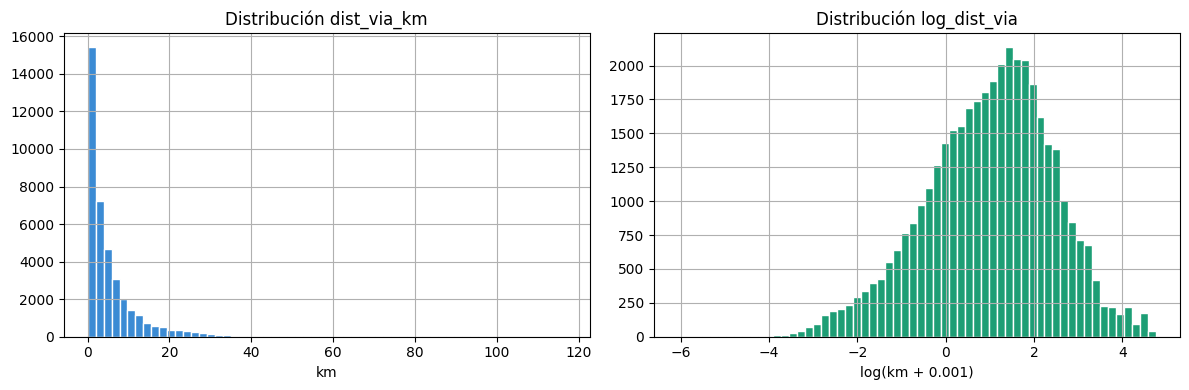

✅ Gráfico guardado


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# PARTE 4 — VALIDACIÓN
# Estadísticas descriptivas + checks de sanidad espacial.
# ══════════════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt

d = alertas_utm["dist_via_km"]

print("─── Estadísticas dist_via_km ───")
print(f"  Mínimo  : {d.min():.4f} km")
print(f"  Máximo  : {d.max():.2f} km")
print(f"  Media   : {d.mean():.4f} km")
print(f"  Mediana : {d.median():.4f} km")
print(f"  Std     : {d.std():.4f} km")

# Checks de sanidad
assert (d >= 0).all(),        "❌ Hay valores negativos"
assert not d.isna().any(),    "❌ Hay NaN"
assert not np.isinf(d).any(), "❌ Hay infinitos"
print("\n✅ Sin valores negativos, NaN ni infinitos")

# Histograma rápido
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
d.hist(bins=60, ax=axes[0], color="#3B8BD4", edgecolor="white")
axes[0].set_title("Distribución dist_via_km")
axes[0].set_xlabel("km")

alertas_utm["log_dist_via"].hist(bins=60, ax=axes[1], color="#1D9E75", edgecolor="white")
axes[1].set_title("Distribución log_dist_via")
axes[1].set_xlabel("log(km + 0.001)")

plt.tight_layout()
plt.savefig(ruta + "dist_via_distribucion.png", dpi=150)
plt.show()
print("✅ Gráfico guardado")

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# PARTE 5 — EXPORTACIÓN FINAL
# Une los atributos originales con las nuevas variables y guarda.
# ══════════════════════════════════════════════════════════════════════════════

# Transferir variables al GeoDataFrame original (con polígonos, en WGS84)
alertas["dist_via_km"]  = alertas_utm["dist_via_km"].values
alertas["log_dist_via"] = alertas_utm["log_dist_via"].values

# Restaurar geometría original de polígono
alertas = alertas.drop(columns=["punto"])
alertas = alertas.set_crs("EPSG:4326", allow_override=True)

# Guardar
alertas.to_file(ruta + "alertas_con_distancia.gpkg", driver="GPKG")
alertas.to_file(ruta + "alertas_con_distancia.shp")

print(f"✅ Exportado: alertas_con_distancia.gpkg + .shp")
print(f"   Filas: {len(alertas):,} | Columnas: {list(alertas.columns)}")

/tmp/ipykernel_22419/1196787271.py:16: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  alertas.to_file(ruta + "alertas_con_distancia.shp")


✅ Exportado: alertas_con_distancia.gpkg + .shp
   Filas: 39,649 | Columnas: ['alert_d', 'ani_lrt', 'fch_lrt', 'area_ha', 'log_are', 'tip_lrt', 'tip_mcr', 'dprtmnt', 'geometry', 'dist_via_km', 'log_dist_via']


/usr/local/lib/python3.12/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Field fch_lrt created as String field, though DateTime requested.
  ogr_write(
/usr/local/lib/python3.12/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'dist_via_km' to 'dist_via_k'
  ogr_write(
/usr/local/lib/python3.12/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'log_dist_via' to 'log_dist_v'
  ogr_write(


In [ ]:
print("Primeras 5 filas del GeoDataFrame 'alertas':")
display(alertas.head())

print("\nInformación general del GeoDataFrame 'alertas' (columnas, tipos de datos y valores no nulos):")
alertas.info()

Primeras 5 filas del GeoDataFrame 'alertas':


,alert_d,ani_lrt,fch_lrt,area_ha,log_are,tip_lrt,tip_mcr,dprtmnt,geometry,dist_via_km,log_dist_via
0,10000000.0,2025.0,2025-02-09,2.87,1.054312,agriculture,antropico_directo,Ucayali,"POLYGON ((-75.46112 -8.70904, -75.46112 -8.709...",1.189952,0.174753
1,10000001.0,2025.0,2025-01-02,6.37,1.851599,agriculture,antropico_directo,Loreto,"POLYGON ((-71.02385 -4.01367, -71.02377 -4.013...",2.436847,0.891115
2,10000002.0,2025.0,2025-02-09,2.54,0.932164,agriculture,antropico_directo,Ucayali,"MULTIPOLYGON (((-75.3302 -8.6174, -75.33026 -8...",5.344136,1.676187
3,10000003.0,2025.0,2025-02-09,1.57,0.451076,agriculture,antropico_directo,Ucayali,"POLYGON ((-75.38873 -8.54389, -75.38859 -8.543...",13.803983,2.625030
4,10000004.0,2025.0,2025-02-25,6.67,1.897620,agriculture,antropico_directo,Ucayali,"POLYGON ((-75.5697 -9.00498, -75.56972 -9.0049...",0.526596,-0.639424



Información general del GeoDataFrame 'alertas' (columnas, tipos de datos y valores no nulos):
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 39649 entries, 0 to 39648
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   alert_d       39649 non-null  float64       
 1   ani_lrt       39649 non-null  float64       
 2   fch_lrt       39649 non-null  datetime64[ms]
 3   area_ha       39649 non-null  float64       
 4   log_are       39649 non-null  float64       
 5   tip_lrt       39649 non-null  object        
 6   tip_mcr       39649 non-null  object        
 7   dprtmnt       39649 non-null  object        
 8   geometry      39649 non-null  geometry      
 9   dist_via_km   39649 non-null  float64       
 10  log_dist_via  39649 non-null  float64       
dtypes: datetime64[ms](1), float64(6), geometry(1), object(3)
memory usage: 3.3+ MB


# Cobertura por año (T - 1) y (T + 1)

In [ ]:
import ee
import geemap
import geopandas as gpd
import pandas as pd
import numpy as np
from google.colab import drive

In [ ]:
import ee
import geemap
import geopandas as gpd
import pandas as pd
import numpy as np
from google.colab import drive

drive.mount('/content/drive')
ee.Authenticate()
ee.Initialize(project='tesis-481703')
print('✅ GEE inicializado')
# ══════════════════════════════════════════════════════════════════════════════
# PARTE 1 — CARGA Y PREPARACIÓN DE ALERTAS
# Lee el shapefile y selecciona las columnas necesarias.
# ══════════════════════════════════════════════════════════════════════════════
RUTA_SHP = "/content/drive/MyDrive/Proyecto_MapBiomas/data_limpia/alertas_con_distancia.shp"

alertas = gpd.read_file(RUTA_SHP)
print(f"Alertas cargadas: {len(alertas):,} | CRS: {alertas.crs}")

# Corregir geometrías inválidas
alertas["geometry"] = alertas.geometry.buffer(0)
alertas = alertas[alertas.geometry.is_valid & alertas.geometry.notna()].copy()
print(f"Alertas válidas: {len(alertas):,}")

# Columnas mínimas para no sobrecargar Colab
cols_keep = ["alert_d", "ani_lrt", "area_ha", "log_are",
             "dist_via_k", "log_dist_v", "geometry"]

# Filtrar cols_keep para incluir solo las columnas que realmente existen en el DataFrame
existing_cols_keep = [col for col in cols_keep if col in alertas.columns]

if len(existing_cols_keep) < len(cols_keep):
    missing_cols = [col for col in cols_keep if col not in alertas.columns]
    print(f"Advertencia: Las siguientes columnas esperadas no se encontraron en el GeoDataFrame y se omitirán: {missing_cols}")

alertas = alertas[existing_cols_keep].copy()
print(f"Columnas finales seleccionadas: {alertas.columns.tolist()}")

# Convertir a FeatureCollection GEE usando geemap
fc_alertas = geemap.geopandas_to_ee(alertas)
print(f"✅ FeatureCollection GEE: {fc_alertas.size().getInfo()} features")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ GEE inicializado
Alertas cargadas: 39,649 | CRS: EPSG:4326
Alertas válidas: 39,649
Columnas finales seleccionadas: ['alert_d', 'ani_lrt', 'area_ha', 'log_are', 'dist_via_k', 'log_dist_v', 'geometry']


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# PARTE 2 — ACCESO A MAPBIOMAS PERÚ COLECCIÓN 3.0
# Asset oficial de MapBiomas Perú Col 3.0.
# Cada banda es un año: classification_2019 ... classification_2024
# ══════════════════════════════════════════════════════════════════════════════
ASSET_MAPBIOMAS = (
    "projects/mapbiomas-public/assets/peru/collection3/mapbiomas_peru_collection3_integration_v1"
)

imagen_mb = ee.Image(ASSET_MAPBIOMAS)

# Verificar bandas disponibles
bandas = imagen_mb.bandNames().getInfo()
print("Bandas disponibles:", bandas)

AÑOS = list(range(2019, 2025))   # 2019–2024
AÑO_MAX = 2024                   # máximo año con datos

def get_banda(anio):
    """Retorna la banda de clasificación para un año dado."""
    return imagen_mb.select(f"classification_{anio}")

Bandas disponibles: ['classification_1985', 'classification_1986', 'classification_1987', 'classification_1988', 'classification_1989', 'classification_1990', 'classification_1991', 'classification_1992', 'classification_1993', 'classification_1994', 'classification_1995', 'classification_1996', 'classification_1997', 'classification_1998', 'classification_1999', 'classification_2000', 'classification_2001', 'classification_2002', 'classification_2003', 'classification_2004', 'classification_2005', 'classification_2006', 'classification_2007', 'classification_2008', 'classification_2009', 'classification_2010', 'classification_2011', 'classification_2012', 'classification_2013', 'classification_2014', 'classification_2015', 'classification_2016', 'classification_2017', 'classification_2018', 'classification_2019', 'classification_2020', 'classification_2021', 'classification_2022', 'classification_2023', 'classification_2024']


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# PARTE 3 — EXTRACCIÓN T-1 (cobertura AÑO ANTERIOR a la alerta)
# Para cada alerta usa ani_lrt para calcular T-1, extrae la moda
# de píxeles dentro del polígono y clasifica en categorías.
# ══════════════════════════════════════════════════════════════════════════════

# Diccionario: clase MapBiomas → categoría T-1
CLASES_T1 = {
    3:  "bosque_primario",
    4:  "formacion_natural",
    41: "vegetacion_secundaria",
}

def extraer_T1(feature):
    anio_alerta = ee.Number(feature.get("ani_lrt"))
    anio_T1     = anio_alerta.subtract(1)

    # Selección condicional de banda según año T-1
    # (GEE no acepta Python dicts directamente, usamos ee.Algorithms.If)
    banda_T1 = ee.Algorithms.If(
        anio_T1.gte(2019).And(anio_T1.lte(AÑO_MAX)),
        imagen_mb.select(
            ee.String("classification_").cat(anio_T1.int().format())
        ),
        ee.Image.constant(-1).rename("classification")  # fuera de rango → -1
    )

    # Reducer: moda dentro del polígono a 30m
    stats = ee.Image(banda_T1).reduceRegion(
        reducer   = ee.Reducer.mode(),
        geometry  = feature.geometry(),
        scale     = 30,
        maxPixels = 1e9
    )

    clase_raw = ee.Number(stats.values().get(0)).int()

    # Clasificar en categoría
    categoria = ee.Algorithms.If(clase_raw.eq(3),  "bosque_primario",
                ee.Algorithms.If(clase_raw.eq(4),  "formacion_natural",
                ee.Algorithms.If(clase_raw.eq(41), "vegetacion_secundaria",
                ee.Algorithms.If(clase_raw.eq(-1), "sin_dato",
                "otros"))))

    # Flag: excluir del modelo si no es cobertura forestal/natural
    flag_excluir = ee.Algorithms.If(
        ee.String(categoria).equals("otros"),
        1,
        ee.Algorithms.If(ee.String(categoria).equals("sin_dato"), 1, 0)
    )

    return feature.set({
        "clase_T1":      categoria,
        "clase_T1_raw":  clase_raw,
        "flag_excluir":  flag_excluir
    })

fc_con_T1 = fc_alertas.map(extraer_T1)
print("✅ T-1 mapeado (lazy evaluation en GEE)")

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# PARTE 4 — EXTRACCIÓN T+1 (destino POST-DEFORESTACIÓN)
# Calcula T+1 = ani_lrt + 1. Si T+1 > AÑO_MAX → NA (control temporal).
# Clasifica la moda en los 5 destinos del modelo.
# ══════════════════════════════════════════════════════════════════════════════

# Grupos de clases MapBiomas → destino
DEST = {
    "D1_agricultura":     [15, 18, 21],
    "D2b_mineria":        [30],
    "D3_suelo_expuesto":  [25],
    "D4_regeneracion":    [41],
    "D5_bosque":          [3, 4],
}

def clase_a_destino(clase_num):
    """Convierte número de clase GEE a destino (string ee.String)."""
    d = ee.Algorithms.If(
        ee.List([15, 18, 21]).contains(clase_num), "D1_agricultura",
    ee.Algorithms.If(
        ee.List([30]).contains(clase_num),          "D2b_mineria",
    ee.Algorithms.If(
        ee.List([25]).contains(clase_num),          "D3_suelo_expuesto",
    ee.Algorithms.If(
        ee.List([41]).contains(clase_num),          "D4_regeneracion",
    ee.Algorithms.If(
        ee.List([3, 4]).contains(clase_num),        "D5_bosque",
        "otros")))))
    return d

def extraer_Tplus1(feature):
    anio_alerta = ee.Number(feature.get("ani_lrt"))
    anio_T1p    = anio_alerta.add(1)

    # Control temporal: si T+1 > AÑO_MAX → sin dato
    tiene_T1p = anio_T1p.lte(AÑO_MAX)

    banda_T1p = ee.Algorithms.If(
        tiene_T1p,
        imagen_mb.select(
            ee.String("classification_").cat(anio_T1p.int().format())
        ),
        ee.Image.constant(-1).rename("classification")
    )

    stats = ee.Image(banda_T1p).reduceRegion(
        reducer   = ee.Reducer.mode(),
        geometry  = feature.geometry(),
        scale     = 30,
        maxPixels = 1e9
    )

    clase_raw = ee.Number(stats.values().get(0)).int()

    destino = ee.Algorithms.If(
        tiene_T1p,
        clase_a_destino(clase_raw),
        "sin_T1p"   # control temporal → NA en pandas
    )

    return feature.set({
        "clase_Tplus1":     clase_raw,
        "destino":          destino,
        "flag_sin_T1p":     ee.Algorithms.If(tiene_T1p, 0, 1)
    })

fc_con_T1_T1p = fc_con_T1.map(extraer_Tplus1)
print("✅ T+1 mapeado")

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# PARTE 5 — HETEROGENEIDAD (ÍNDICE DE GINI)
# Calcula la distribución de clases dentro de cada polígono en T+1.
# Gini = 1 - suma(p²). Alta heterogeneidad = polígono mixto → flag_mixta=1
# ══════════════════════════════════════════════════════════════════════════════

# Todas las clases posibles en MapBiomas Perú (simplificado)
CLASES_MB = [3, 4, 11, 12, 15, 18, 21, 24, 25, 29, 30, 33, 41]

def calcular_gini(feature):
    anio_alerta = ee.Number(feature.get("ani_lrt"))
    anio_T1p    = anio_alerta.add(1).min(AÑO_MAX)  # clamp al máximo

    banda = imagen_mb.select(
        ee.String("classification_").cat(anio_T1p.int().format())
    )

    # Histograma de píxeles por clase dentro del polígono
    hist = banda.reduceRegion(
        reducer   = ee.Reducer.frequencyHistogram(),
        geometry  = feature.geometry(),
        scale     = 30,
        maxPixels = 1e9
    ).values().get(0)

    hist_dict = ee.Dictionary(hist)
    total     = hist_dict.values().reduce(ee.Reducer.sum())

    # Proporción por clase y suma de cuadrados
    proporciones = hist_dict.values().map(
        lambda v: ee.Number(v).divide(ee.Number(total))
    )
    suma_cuadrados = proporciones.reduce(ee.Reducer.sum())  # incorrecto para cuadrados

    # Cálculo correcto: suma de p²
    suma_p2 = proporciones.map(
        lambda p: ee.Number(p).pow(2)
    ).reduce(ee.Reducer.sum())

    gini = ee.Number(1).subtract(suma_p2)

    flag_mixta = ee.Algorithms.If(gini.gt(0.5), 1, 0)

    return feature.set({
        "gini":       gini,
        "flag_mixta": flag_mixta
    })

fc_final = fc_con_T1_T1p.map(calcular_gini)
print("✅ Heterogeneidad (Gini) calculada")

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# PARTE 6 — CONTROL TEMPORAL (ya integrado en T+1, pero verificamos)
# Alertas con ani_lrt = 2024 → T+1 = 2025 → sin dato → flag_sin_T1p = 1
# Se mantienen para análisis descriptivo, pero se excluyen del modelo.
# ══════════════════════════════════════════════════════════════════════════════
# Este bloque es solo informativo — el control ya está en extraer_Tplus1()

alertas_sin_T1p = alertas[alertas["ani_lrt"] == AÑO_MAX]
print(f"Alertas sin T+1 (año {AÑO_MAX}): {len(alertas_sin_T1p):,}")
print("→ Se asigna NA en 'destino' | flag_sin_T1p = 1")
print("→ Se conservan para análisis descriptivo únicamente")

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# PARTE 7 — DESCARGA Y EXPORTACIÓN FINAL
# Descarga el FeatureCollection a pandas, limpia tipos, reemplaza
# marcadores de NA, y guarda como CSV + GPKG.
# ══════════════════════════════════════════════════════════════════════════════
import time

RUTA_OUT = "/content/drive/MyDrive/Proyecto_MapBiomas/data_limpia/"

# ── Opción A: Export a Drive (asíncrono, recomendado para datasets grandes) ──
task = ee.batch.Export.table.toDrive(
    collection  = fc_final,
    description = "alertas_con_trayectoria",
    folder      = "Proyecto_MapBiomas/data_limpia",
    fileNamePrefix = "alertas_con_trayectoria",
    fileFormat  = "CSV",
    selectors   = [
        "alert_d", "ani_lrt", "area_ha", "log_are",
        "dist_via_km", "log_dist_via",
        "clase_T1", "clase_T1_raw",
        "clase_Tplus1", "destino",
        "gini", "flag_mixta", "flag_excluir", "flag_sin_T1p"
    ]
)
task.start()
print(f"✅ Export iniciado → Task ID: {task.id}")
print("   Monitorear en: https://code.earthengine.google.com/tasks")

# ── Opción B: descarga directa a Colab (solo si dataset < ~50k filas) ───────
# df = geemap.ee_to_pandas(fc_final)

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELDA POST-EXPORT — Limpieza y guardado GPKG (después de que termine la tarea)
# ══════════════════════════════════════════════════════════════════════════════

# Cargar el CSV exportado por GEE
df = pd.read_csv(RUTA_OUT + "alertas_con_trayectoria.csv")

# Reemplazar marcadores de sin dato
df["destino"]      = df["destino"].replace("sin_T1p", pd.NA)
df["clase_T1_raw"] = pd.to_numeric(df["clase_T1_raw"], errors="coerce")

# Estadísticas rápidas
print("─── Resumen T-1 ───")
print(df["clase_T1"].value_counts())
print("\n─── Resumen destino T+1 ───")
print(df["destino"].value_counts(dropna=False))
print(f"\n─── Gini ───")
print(df["gini"].describe().round(4))
print(f"\nFlag mixta  (Gini>0.5): {df['flag_mixta'].sum():,}")
print(f"Flag excluir           : {df['flag_excluir'].sum():,}")
print(f"Flag sin T+1           : {df['flag_sin_T1p'].sum():,}")

# Guardar CSV limpio
df.to_csv(RUTA_OUT + "alertas_con_trayectoria.csv", index=False)
print("\n✅ CSV guardado")

# GPKG: unir con geometría original
alertas_geo = gpd.read_file(RUTA_SHP)[["alert_d", "geometry"]].to_crs("EPSG:4326")
df_geo = alertas_geo.merge(df, on="alert_d", how="inner")
gdf_final = gpd.GeoDataFrame(df_geo, crs="EPSG:4326")
gdf_final.to_file(RUTA_OUT + "alertas_con_trayectoria.gpkg", driver="GPKG")
print("✅ GPKG guardado")
print(f"\nColumnas finales: {list(gdf_final.columns)}")